In [1]:
import numpy as np
from astroquery.vizier import Vizier
import matplotlib.pyplot as plt


In [ ]:
v = Vizier(columns=["**"], row_limit=-1)     # v ist Anfrage Objekt mit row limit -1 damit nicht nur die standard ersten 50 einträge geladen werden 
v.VIZIER_SERVER = "vizier.cfa.harvard.edu"
tbl_1 = v.get_catalogs("J/AJ/135/928")[0]     # [0] damit haupttabelle des catalogs geladen wird
tbl_2 = v.get_catalogs("J/ApJ/831/134")[0]
print(tbl_1.colnames)
print(tbl_2.colnames)

['recno', 'SDSS', 'z', 'imag', 'Hfrac', 'phi', 'S/N', 'S/N(H)', 'gMAG', 'logL1', 'logL2', 'sigma', 'e_sigma', 'Csigma', 'FWHM.b', 'e_FWHM.b', 'FWHM.a', 'e_FWHM.a', 'logM', 'e_logM', 'f_logM', 'Lratio', 'DR7', 'Sloan', 'SimbadName', '_RA', '_DE']
['recno', 'Name', 'f_Name', 'Dist', 'e_Dist', 'logBHMass', 'E_logBHMass', 'e_logBHMass', 'logsigma', 'e_logsigma', 'logLk', 'e_logLk', 'logRe', 'e_logRe', 'cov', 'C28', 'e_C28', 'logAGN', 'e_logAGN', 'Meth', 'Refs', 'SimbadName', 'NED', '_RA', '_DE']


In [9]:
raw_mbh_shen = np.array(tbl_1["logM"], dtype=float)
raw_sigma_shen = np.array(tbl_1["Csigma"], dtype=float)

mask_1 = (~np.isnan(raw_mbh_shen)) & (~np.isnan(raw_sigma_shen)) & (raw_sigma_shen > 0)  # Maske um ungültige Daten zu filtern (leer,sigma negativ)


x_sigma_shen = np.log10(raw_sigma_shen[mask_1])  #per maske gefilterte daten
y_mbh_shen = raw_mbh_shen[mask_1]

raw_mbh_bosch = np.array(tbl_2["logBHMass"], dtype=float)
raw_sigma_bosch = np.array(tbl_2["logsigma"], dtype=float)

mask_2 = (~np.isnan(raw_mbh_bosch)) & (~np.isnan(raw_sigma_bosch)) & (raw_sigma_bosch > 0)

x_sigma_bosch = raw_sigma_bosch[mask_2] 
y_mbh_bosch = raw_mbh_bosch[mask_2]

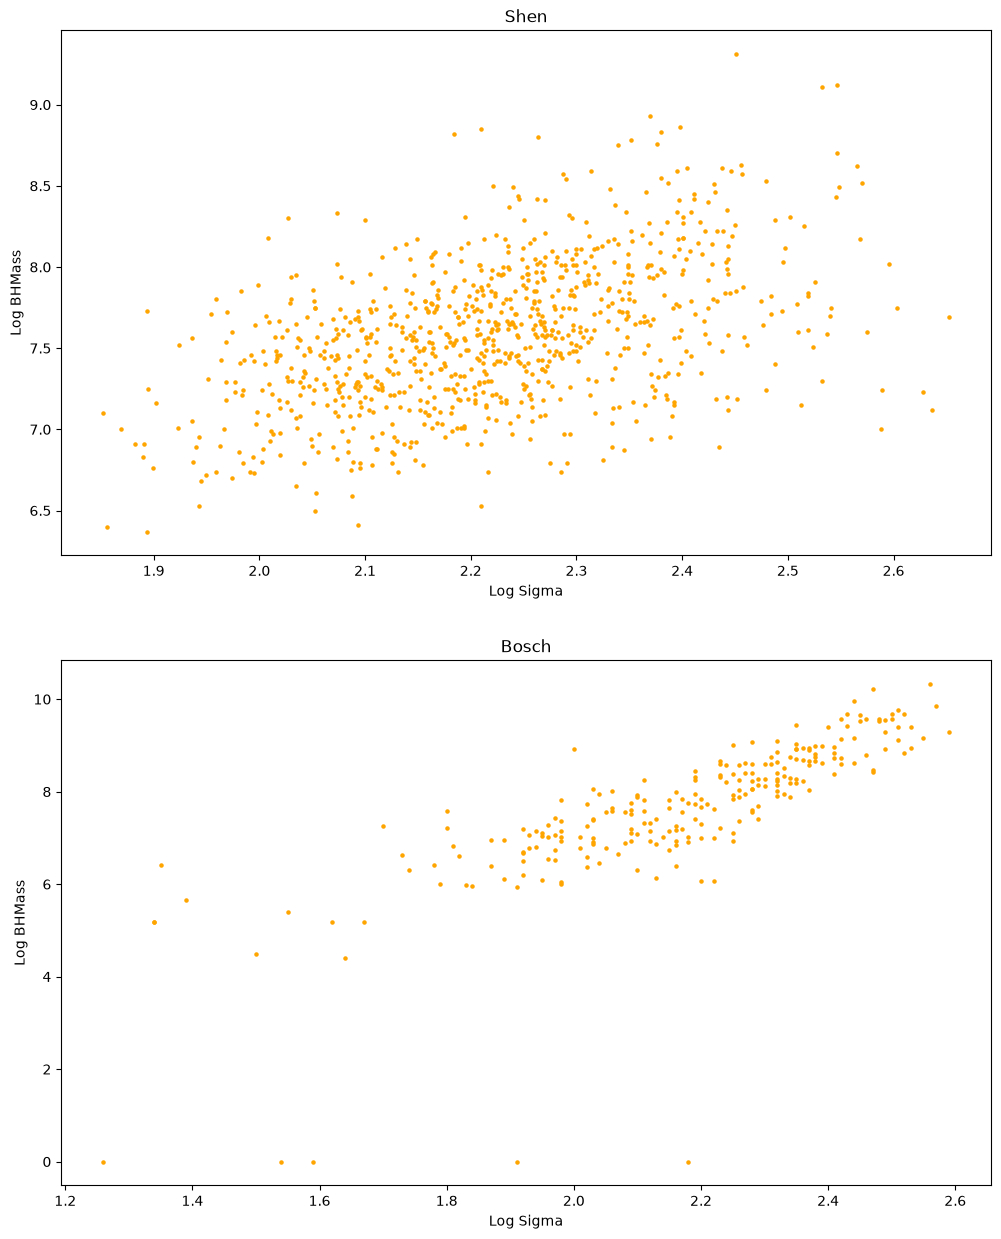

In [14]:

fig, ax = plt.subplots(2, 1, figsize=(12, 15))
ax[0].scatter(x_sigma_shen, y_mbh_shen, s=5, alpha=1, color="orange")
ax[0].set_title("Shen")
ax[0].set_xlabel("Log Sigma")
ax[0].set_ylabel("Log BHMass")
ax[1].scatter(x_sigma_bosch, y_mbh_bosch, s=5, alpha=1, color="orange")
ax[1].set_title("Bosch")
ax[1].set_xlabel("Log Sigma")
ax[1].set_ylabel("Log BHMass")
plt.show()

